# Этап 6. Интерпретация модели: SHAP

**Вопрос:** как именно температура меняет прогноз LightGBM из этапа 5? Совпадает ли это с «клюшкой» и порогом 10 °C из этапа 4?

**SHAP** раскладывает каждый прогноз на вклады признаков:

прогноз = средний прогноз + вклад `borough` + вклад `roll7` + … + вклад температуры

Наша модель с `objective="poisson"` работает в **логарифмах**, как регрессия Пуассона. Поэтому вклады складываются в логарифме, а `exp(вклад) − 1` даёт **проценты**. Это удобно: вклад температуры можно сразу сравнить с +4,2 % на 5 °C из этапа 4.

Код подготовки данных и обучения теперь лежит в `src/forecast.py`: те же функции, что в ноутбуке 05, только без копирования.

*Ноутбук написал Claude. Твоя задача: прочитать, разобраться и задать вопросы.*

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from forecast import load_features, split, train_lgbm, shift_temperature, FEATS_FULL

df = load_features()
train, valid, test = split(df)
model = train_lgbm(train, valid, FEATS_FULL)
print(f"деревьев: {model.best_iteration_}, тест: {len(test)} строк")

/Users/marinakomkova/heat-ems-nyc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


деревьев: 1092, тест: 3190 строк


## 1. Считаем SHAP для тестового периода

In [2]:
explainer = shap.TreeExplainer(model)
sv = explainer(test[FEATS_FULL])            # SHAP-значения: строка × признак

# проверка: средний прогноз + сумма вкладов = прогноз модели (в логарифмах)
same = np.allclose(np.exp(sv.base_values + sv.values.sum(axis=1)), model.predict(test[FEATS_FULL]), rtol=1e-4)
print("Разложение сходится с прогнозом:", same)

shap_df = pd.DataFrame(sv.values, columns=FEATS_FULL, index=test.index)

Разложение сходится с прогнозом: True


## 2. Общая картина

На графике **beeswarm** каждая точка — один день в одном районе. По горизонтали — вклад признака в прогноз, цвет — значение признака (красный — большое, синий — маленькое).

Например, для `temperature_2m_max`: красные точки справа означают «жаркий день → прогноз выше».

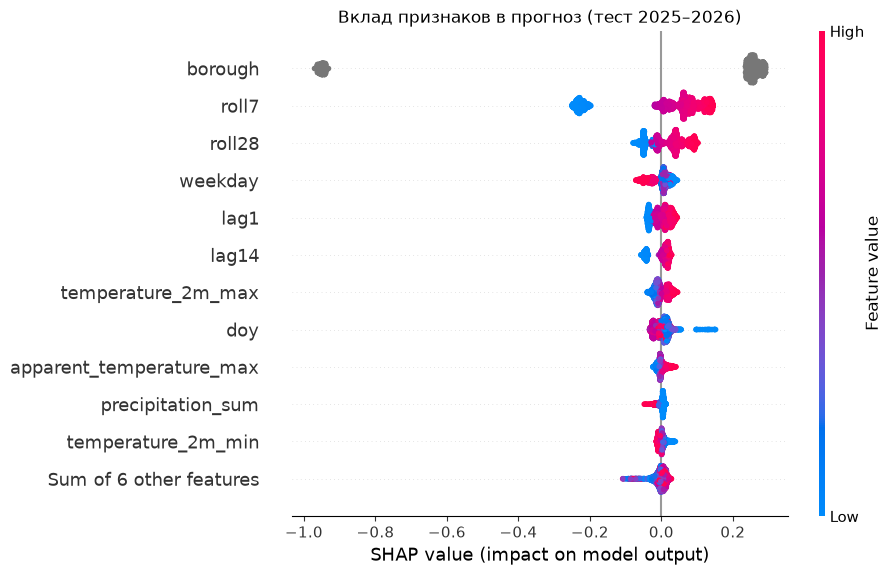

In [3]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("Вклад признаков в прогноз (тест 2025–2026)")
plt.show()

**Как читать:** `borough` сверху, потому что задаёт уровень района. Дальше `roll7` и `roll28`: прогноз держится за «сколько было на этой неделе». Температура — самый сильный погодный признак, примерно на уровне дня недели.

## 3. Форма эффекта температуры

У модели **четыре** температурных признака: `temperature_2m_max`, `temperature_2m_min`, `apparent_temperature_max`, `heat`. Они сильно связаны, и модель делит эффект между ними как ей удобно. Поэтому **складываем** их вклады в один «эффект температуры» и переводим в проценты.

Для сравнения рисуем кривую из этапа 4: +0,82 % на каждый градус выше 10 °C.

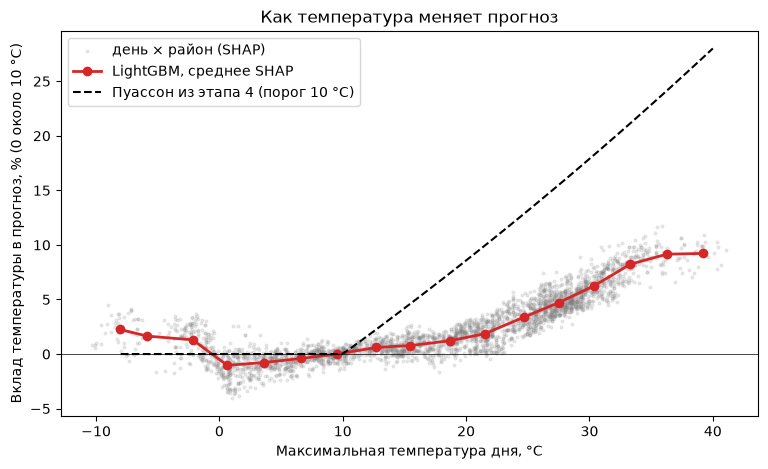

,t,effect0,days
t_bin,,,
"(-10, -7]",-8.1,2.3,32
"(-7, -4]",-5.8,1.6,22
"(-4, -1]",-2.2,1.3,125
"(-1, 2]",0.6,-1.0,204
"(2, 5]",3.6,-0.8,208
"(5, 8]",6.6,-0.4,196
"(8, 11]",9.5,0.0,227
"(11, 14]",12.7,0.6,179
"(14, 17]",15.5,0.8,235


In [4]:
TEMP = ["temperature_2m_max", "temperature_2m_min", "apparent_temperature_max", "heat"]
test["temp_effect"] = (np.exp(shap_df[TEMP].sum(axis=1)) - 1) * 100

test["t_bin"] = pd.cut(test["temperature_2m_max"], bins=range(-10, 44, 3))
curve = test.groupby("t_bin", observed=True).agg(t=("temperature_2m_max", "mean"),
                                                 effect=("temp_effect", "mean"),
                                                 days=("temp_effect", "size"))

# чтобы сравнивать формы, сдвигаем обе кривые к нулю около порога 10 °C
ref = curve.loc[(curve["t"] > 8) & (curve["t"] < 12), "effect"].mean()
curve["effect0"] = curve["effect"] - ref
t = np.linspace(-8, 40, 100)
poisson = (np.exp(0.00823 * np.clip(t - 10, 0, None)) - 1) * 100     # коэффициент из этапа 4

plt.figure(figsize=(9, 5))
plt.scatter(test["temperature_2m_max"], test["temp_effect"] - ref, s=4, alpha=0.15, color="grey", label="день × район (SHAP)")
plt.plot(curve["t"], curve["effect0"], "o-", color="tab:red", linewidth=2, label="LightGBM, среднее SHAP")
plt.plot(t, poisson, "--", color="black", label="Пуассон из этапа 4 (порог 10 °C)")
plt.axhline(0, color="black", linewidth=0.5)
plt.xlabel("Максимальная температура дня, °C")
plt.ylabel("Вклад температуры в прогноз, % (0 около 10 °C)")
plt.title("Как температура меняет прогноз")
plt.legend()
plt.show()
curve[["t", "effect0", "days"]].round(1)

**Что видно:**
1. **Форма та же — «клюшка».** Минимум около 0–10 °C, выше 12 °C вклад растёт и доходит до **+9 %** в дни выше 35 °C. Модель сама, без подсказок, нашла порог из этапа 4. Новое: в сильный мороз (ниже −4 °C) вклад тоже чуть выше нуля (+1–2 %): возможно, гололёд и переохлаждение. Но таких дней в тесте мало (~50).
2. **Наклон меньше, чем у Пуассона.** Причина — лаги. Жара обычно держится несколько дней, поэтому к 3-му дню волны `roll7` и `lag1` **уже** выросли, и модель частично «знает» про жару через них. В Пуассоне из этапа 4 лагов не было, и весь эффект достался температуре. Это не противоречие: Пуассон отвечает «на сколько жара увеличивает вызовы», а SHAP — «сколько **новой** информации температура добавляет к тому, что модель уже знает».
3. **Выше ~35 °C кривая выходит на плато.** Деревья не умеют экстраполировать: дней выше 35 °C в обучении очень мало, и модель отвечает «как в самый жаркий из виденных дней». Об этом подробнее в шаге 5.

## 4. Разбор одного дня: Бруклин, 24 июня 2025 (40 °C)

**Waterfall** показывает, как модель шла от среднего прогноза к прогнозу на этот день: какие признаки толкнули вверх (красные), какие вниз (синие). Числа в логарифмах; `+0,05` ≈ `+5 %`.

Факт: 1471, прогноз: 1342, вклад температуры: +8.1 %


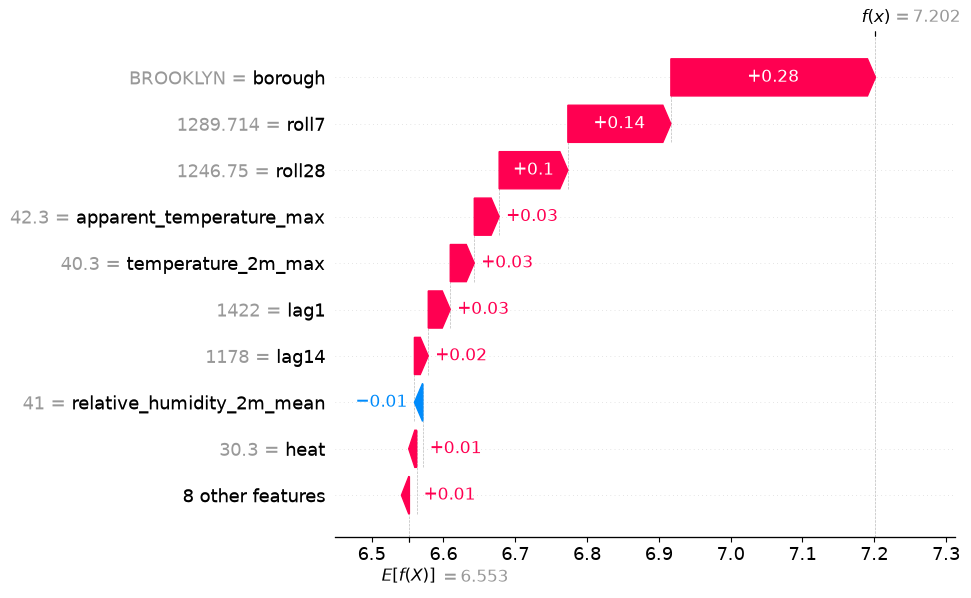

In [5]:
row = test.index.get_loc(test[(test["date"] == "2025-06-24") & (test["borough"] == "BROOKLYN")].index[0])
day = test.iloc[row]
print(f"Факт: {day['n_calls']}, прогноз: {model.predict(test[FEATS_FULL].iloc[[row]])[0]:.0f}, "
      f"вклад температуры: {day['temp_effect']:+.1f} %")
shap.plots.waterfall(sv[row], max_display=10)

## 5. Сценарий «на 5 °C теплее» и предел модели

Сдвигаем все температурные признаки тестового периода на +5 °C (функция `shift_temperature`) и смотрим, на сколько изменится прогноз. Это пригодится в этапе 7 для расчёта бригад.

In [6]:
p_now  = model.predict(test[FEATS_FULL])
p_warm = model.predict(shift_temperature(test, 5)[FEATS_FULL])
test["warm_%"] = (p_warm / p_now - 1) * 100

scen = test.groupby("t_bin", observed=True).agg(t=("temperature_2m_max", "mean"), plus5=("warm_%", "mean")).round(1)
summer = test["month"].isin([6, 7, 8]).to_numpy()
print(f"Лето целиком: +5 °C → +{(p_warm[summer].sum() / p_now[summer].sum() - 1) * 100:.1f} % вызовов (LightGBM)")
print(f"Для сравнения, Пуассон из этапа 4: +4,2 % [3,9 … 4,5] выше 10 °C")
scen

Лето целиком: +5 °C → +3.2 % вызовов (LightGBM)
Для сравнения, Пуассон из этапа 4: +4,2 % [3,9 … 4,5] выше 10 °C


,t,plus5
t_bin,,
"(-10, -7]",-8.1,-0.8
"(-7, -4]",-5.8,-1.9
"(-4, -1]",-2.2,-2.1
"(-1, 2]",0.6,0.5
"(2, 5]",3.6,1.1
"(5, 8]",6.6,1.2
"(8, 11]",9.5,1.1
"(11, 14]",12.7,0.7
"(14, 17]",15.5,2.0


**Как читать:** в тёплом диапазоне (15–32 °C) +5 °C дают +2…+3,5 % вызовов. Уже с 32 °C эффект падает, а для дней, которые и так были 35 °C и выше, модель говорит «почти +0 %»: 40 °C + 5 = 45 °C, такого она никогда не видела, и деревья дают тот же ответ, что для 40 °C.

**Это важный урок про деревья:** их нельзя использовать для сценариев «за пределами данных». Для этапа 7 (сценарий «+5 °C» и климатическое будущее) правильнее брать **коэффициент Пуассона из этапа 4**, который продолжает клюшку дальше, а LightGBM — для обычного прогноза на завтра.

## Итоги этапа 6

**Черновик Claude, перепиши своими словами:**
1. SHAP подтверждает «клюшку»: модель сама нашла, что температура начинает поднимать прогноз примерно с 5–10 °C, и вклад растёт до ~+9 % в дни выше 35 °C.
2. Наклон в ML-модели меньше, чем в Пуассоне, потому что часть эффекта жары модель видит через лаги: волна жары длится несколько дней.
3. Деревья не экстраполируют: выше ~35 °C прогноз упирается в плато. Для сценариев «+5 °C» берём Пуассона, для прогноза на завтра — LightGBM.

**Строка для README:** *SHAP-анализ показал, что LightGBM самостоятельно выучил пороговую зависимость от температуры (рост выше ~10 °C), согласующуюся с регрессией Пуассона; для климатических сценариев за пределами наблюдённых температур используется параметрическая модель, так как деревья не экстраполируют.*